# Bridge crack severity assessment — Colab runner (your Drive paths pre-filled)

**Before running:** Runtime → Change runtime type → **T4 GPU** → Save. Then run the cells top to bottom (Shift+Enter).

Expected in your Google Drive, folder `MyDrive/MINI_PROJECT/`:
- `SSL-For-Bridge-Crack-Classification-severity(final).zip`
- `DATA_Maguire_20180517_ALL (2).zip`  (SDNET2018 dataset)

## Step 1 — Check the GPU

In [ ]:
import torch
print("PyTorch:", torch.__version__)
print("GPU available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU name:", torch.cuda.get_device_name(0))
else:
    print("NO GPU -> Runtime > Change runtime type > T4 GPU, then restart and rerun from the top.")

PyTorch: 2.11.0+cu130
GPU available: True
GPU name: Tesla T4


## Step 2 — Connect Google Drive (click Allow when asked)

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## Step 3 — Unpack the project from Drive

In [ ]:
import os, glob

DRIVE_DIR   = "/content/drive/MyDrive/MINI_PROJECT"
PROJECT_ZIP = f"{DRIVE_DIR}/SSL-For-Bridge-Crack-Classification-severity(final).zip"
DATASET_ZIP = f"{DRIVE_DIR}/DATA_Maguire_20180517_ALL (2).zip"
BACKUP      = f"{DRIVE_DIR}/outputs"          # results get saved here

for p in (PROJECT_ZIP, DATASET_ZIP):
    assert os.path.exists(p), f"Not found in Drive: {p}"

!rm -rf /content/project
!unzip -q -o "$PROJECT_ZIP" -d /content/project

# the zip may contain nested folders, so locate the one that holds severity/
hits = glob.glob("/content/project/**/severity/make_severity_labels.py", recursive=True)
assert hits, "Could not find severity/make_severity_labels.py inside the project zip"
PROJECT = os.path.dirname(os.path.dirname(hits[0]))
os.chdir(PROJECT)
print("Working folder:", os.getcwd())
print(sorted(os.listdir(".")))

shell-init: error retrieving current directory: getcwd: cannot access parent directories: No such file or directory
Working folder: /content/project/SSL-For-Bridge-Crack-Classification-main
['.gitignore', 'README.md', 'check_dataset.py', 'create_better_plots.py', 'evaluate_fair_comparison.py', 'evaluate_mae_small.py', 'evaluate_moco_v3.py', 'requirements.txt', 'results', 'setup_env.sh', 'severity']


## Step 4 — Install the few extra libraries

In [ ]:
!pip install -q scikit-image joblib tqdm

## Step 5 — Unpack the dataset and arrange it as Decks / Pavements / Walls
Copying 56,000 images straight from Drive is slow, so the zip is unpacked onto Colab's local disk (takes a few minutes).
The original SDNET2018 uses folders `D / P / W`; this cell finds them and builds the layout the code expects.

In [ ]:
!rm -rf /content/data
!unzip -q -o "$DATASET_ZIP" -d /content/data

import os
import glob

# Check if the extracted contents contain a nested SDNET2018.zip
nested_zips = glob.glob("/content/data/**/SDNET2018.zip", recursive=True)
if nested_zips:
    print(f"Found nested zip file: {nested_zips[0]}. Extracting it...")
    target_dir = os.path.dirname(nested_zips[0])
    !unzip -q -o "{nested_zips[0]}" -d "{target_dir}"

# Let's inspect the extracted folder structure now
print("\n--- Top-level contents in /content/data ---")
for root, dirs, files in os.walk("/content/data"):
    depth = root.replace("/content/data", "").count(os.sep)
    if depth <= 2:
        print(f"{'  ' * depth} Folder: {os.path.basename(root)}/ contains {len(dirs)} folders and {len(files)} files")

os.makedirs("/content/archive", exist_ok=True)

# Try searching for both 'CD'/'CP'/'CW' AND alternative SDNET2018 names like 'D'/'P'/'W'
mapping = {"Decks": ["CD", "D"], "Pavements": ["CP", "P"], "Walls": ["CW", "W"]}

for name, targets in mapping.items():
    hits = []
    for target in targets:
        hits = [r for r, d, f in os.walk("/content/data")
                if os.path.basename(r).upper() == target.upper() and "__MACOSX" not in r]
        if hits:
            break

    assert hits, f"Could not find any of {targets} folders inside the dataset zip"
    link = f"/content/archive/{name}"
    if os.path.lexists(link):
        os.remove(link)
    os.symlink(os.path.dirname(hits[0]), link)
    print(f"\nSuccessfully mapped: {name} -> {os.path.dirname(hits[0])}")

from severity.common import list_dataset
paths, targets, surfaces = list_dataset("/content/archive")
print(f"\n{len(paths)} images in total, {(targets == 0).sum()} cracked, {(targets == 1).sum()} uncracked")
assert len(paths) > 50000, "Expected roughly 56,000 images - check the dataset zip contents"

Found nested zip file: /content/data/DATA_Maguire_20180517_ALL/SDNET2018.zip. Extracting it...

--- Top-level contents in /content/data ---
 Folder: data/ contains 1 folders and 0 files
   Folder: DATA_Maguire_20180517_ALL/ contains 3 folders and 2 files
     Folder: D/ contains 2 folders and 0 files
     Folder: P/ contains 2 folders and 0 files
     Folder: W/ contains 2 folders and 0 files

Successfully mapped: Decks -> /content/data/DATA_Maguire_20180517_ALL/D

Successfully mapped: Pavements -> /content/data/DATA_Maguire_20180517_ALL/P

Successfully mapped: Walls -> /content/data/DATA_Maguire_20180517_ALL/W

56092 images in total, 8484 cracked, 47608 uncracked


## Step 6 — (Optional) quick self-test of the crack-measurement code

In [ ]:
!python severity/selftest.py

blank      : {'length_px': 0.0, 'mean_width_px': 0.0, 'p90_width_px': 0.0, 'max_width_px': 0.0, 'area_px': 0.0, 'coverage': 0.0, 'n_components': 0.0}
thickness 1: length=215  mean_w=1.04  p90_w=1.00  coverage=0.0067
thickness 3: length=217  mean_w=4.50  p90_w=5.00  coverage=0.0178
thickness 6: length=219  mean_w=6.13  p90_w=7.00  coverage=0.0250
length_frac 0.3: length=78
length_frac 0.6: length=137
length_frac 1.0: length=220

OK: width and length measurements respond monotonically on synthetic cracks.


## Step 7 — Measure cracks and create the proxy severity labels
CPU only, several minutes. Then **look at the contact sheet** to check the labels.

In [ ]:
!python severity/make_severity_labels.py --data_dir /content/archive --workers 2 --spotcheck 12

Dataset: 56092 images, 8484 cracked -> measuring cracked images
Measuring cracks: 100% 8484/8484 [14:42<00:00,  9.61it/s]
Saved measurements -> /content/project/SSL-For-Bridge-Crack-Classification-main/severity/crack_measurements.csv

=== Severity label summary ===
score = area [fraction of image], cut-offs = [0.0058, 0.01427]
cracked images measured : 8484
undetected (excluded)   : 1699
  Minor    train   1811
  Minor    test     429
  Moderate train   1815
  Moderate test     438
  Severe   train   1818
  Severe   test     474
Saved -> /content/project/SSL-For-Bridge-Crack-Classification-main/severity/severity_labels.csv
Contact sheet (top = image, bottom = detected crack; one row per auto class): /content/project/SSL-For-Bridge-Crack-Classification-main/severity/spotcheck_contact_sheet.png
Spot-check template: /content/project/SSL-For-Bridge-Crack-Classification-main/severity/spotcheck_template.csv
  -> fill 'human_severity' with 0=Minor 1=Moderate 2=Severe (judge the image, ideally

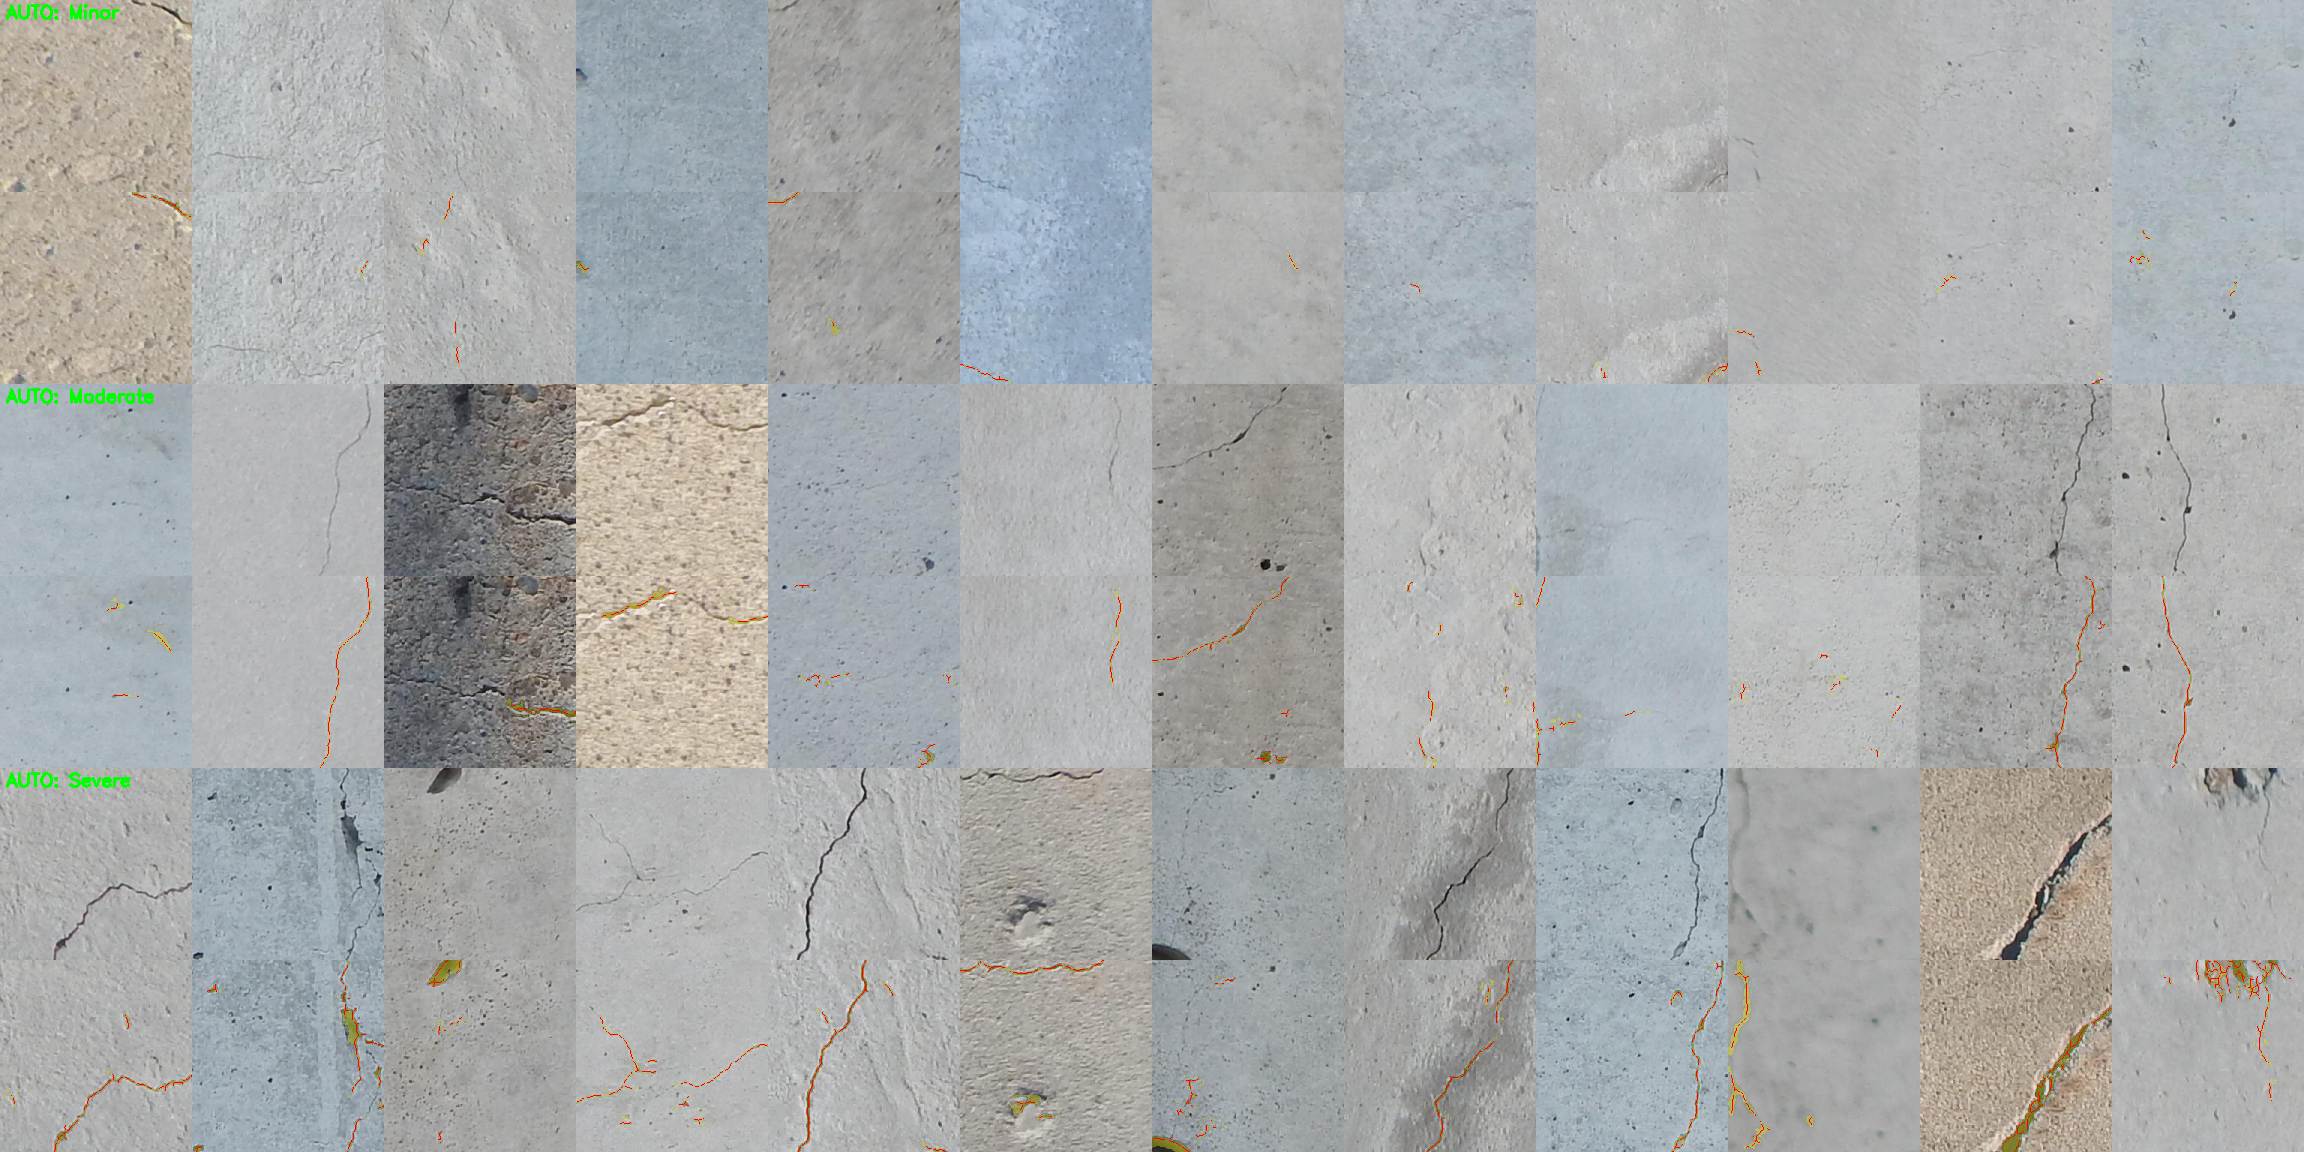

In [ ]:
# Top of each row = photo, bottom = detected crack. Does the red/yellow overlay follow the real cracks?
from IPython.display import Image, display
display(Image("severity/spotcheck_contact_sheet.png"))

## Step 8 — Extract DINOv2 features (the slow GPU step; saved to Drive right after)

In [ ]:
!python severity/extract_features.py --data_dir /content/archive --num_workers 2

56092 images; device = cuda
Downloading: "https://github.com/facebookresearch/dinov2/zipball/main" to /root/.cache/torch/hub/main.zip
/root/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/swiglu_ffn.py:51: UserWarning: xFormers is not available (SwiGLU)
  warnings.warn("xFormers is not available (SwiGLU)")
/root/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/attention.py:33: UserWarning: xFormers is not available (Attention)
  warnings.warn("xFormers is not available (Attention)")
/root/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/block.py:40: UserWarning: xFormers is not available (Block)
  warnings.warn("xFormers is not available (Block)")
Downloading: "https://dl.fbaipublicfiles.com/dinov2/dinov2_vits14/dinov2_vits14_pretrain.pth" to /root/.cache/torch/hub/checkpoints/dinov2_vits14_pretrain.pth
100% 84.2M/84.2M [00:00<00:00, 335MB/s]
DINOv2 features: 100% 439/439 [03:49<00:00,  1.91it/s]
Saved (56092, 384) features -> /content/project/SSL-For-

In [ ]:
import shutil
os.makedirs(BACKUP, exist_ok=True)
for f in ["features_dinov2_vits14.npz", "crack_measurements.csv", "severity_labels.csv", "severity_cutoffs.json"]:
    shutil.copy(f"severity/{f}", BACKUP)
print("Backed up features + labels to", BACKUP)

Backed up features + labels to /content/drive/MyDrive/MINI_PROJECT/outputs


## Step 9 — Train stage 1 (crack / no crack)

In [ ]:
!python severity/train_crack_detector.py

Stage 1 (crack vs no crack) test accuracy: 0.9416
  'Crack' class  precision=0.8977  recall=0.6930  F1=0.7822
  (compare with results/results.json -> linear -> 'DINOv2 ViT-S/14' -> '1.0')
Saved -> /content/project/SSL-For-Bridge-Crack-Classification-main/severity/models/crack_detector.joblib


## Step 10 — Train and evaluate stage 2 (severity)

In [ ]:
!python severity/train_severity.py

Severity-labeled cracks: train=5444  test=1341
  Minor     train= 1811  test=  429
  Moderate  train= 1815  test=  438
  Severe    train= 1818  test=  474

Reference (circular) raw-measurement classifier: acc=0.993  macro-F1=0.993
Majority-class baseline accuracy: 0.353

%labels  n_train   accuracy        macro-F1        Minor<->Severe
     5      273   0.616±0.009    0.615±0.008    0.049
    10      545   0.632±0.005    0.632±0.004    0.043
    20     1089   0.663±0.007    0.661±0.007    0.037
    50     2723   0.694±0.007    0.692±0.007    0.030
   100     5444   0.706±0.000    0.703±0.000    0.030

Saved severity head -> /content/project/SSL-For-Bridge-Crack-Classification-main/severity/models/severity_head.joblib
Confusion matrix (rows = true, cols = predicted; Minor/Moderate/Severe):
[[331  74  24]
 [100 245  93]
 [ 16  87 371]]

Two-stage: stage 1 passes 989/1341 true cracks (recall 0.738); end-to-end severity accuracy 0.522
Saved results -> /content/project/SSL-For-Bridge-Crack-

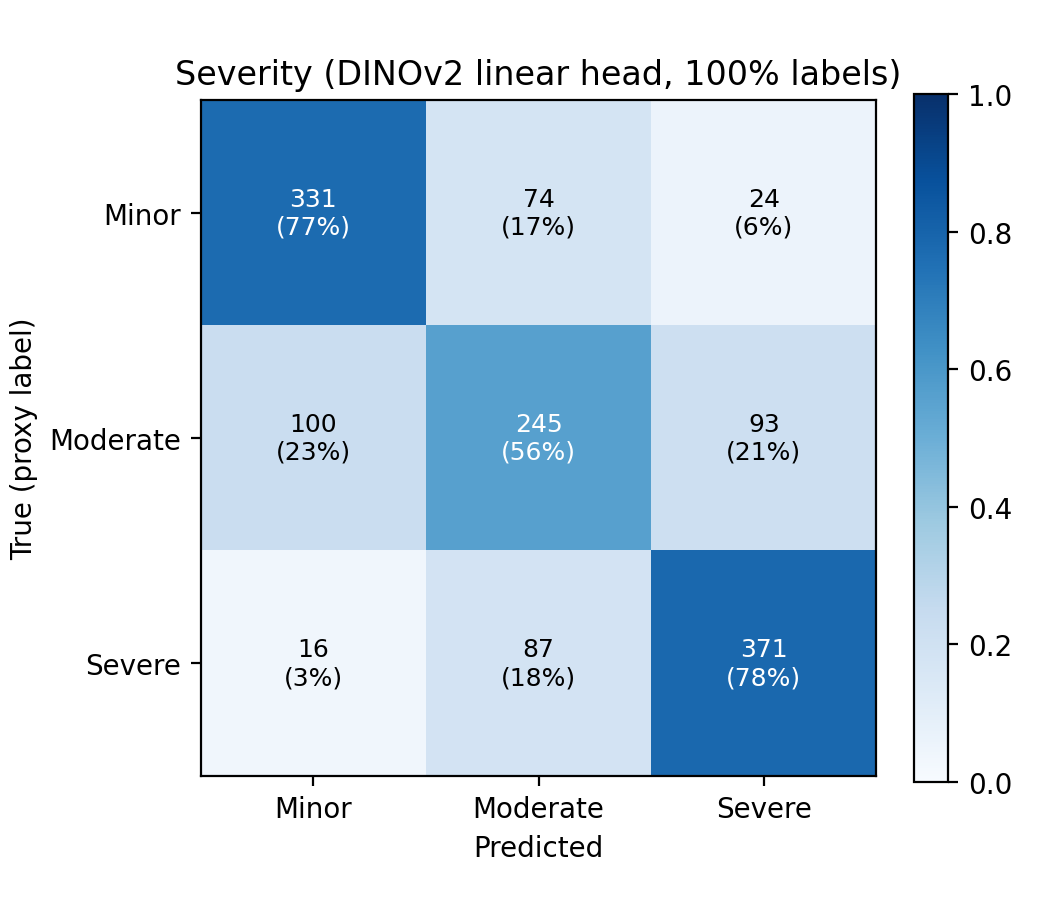

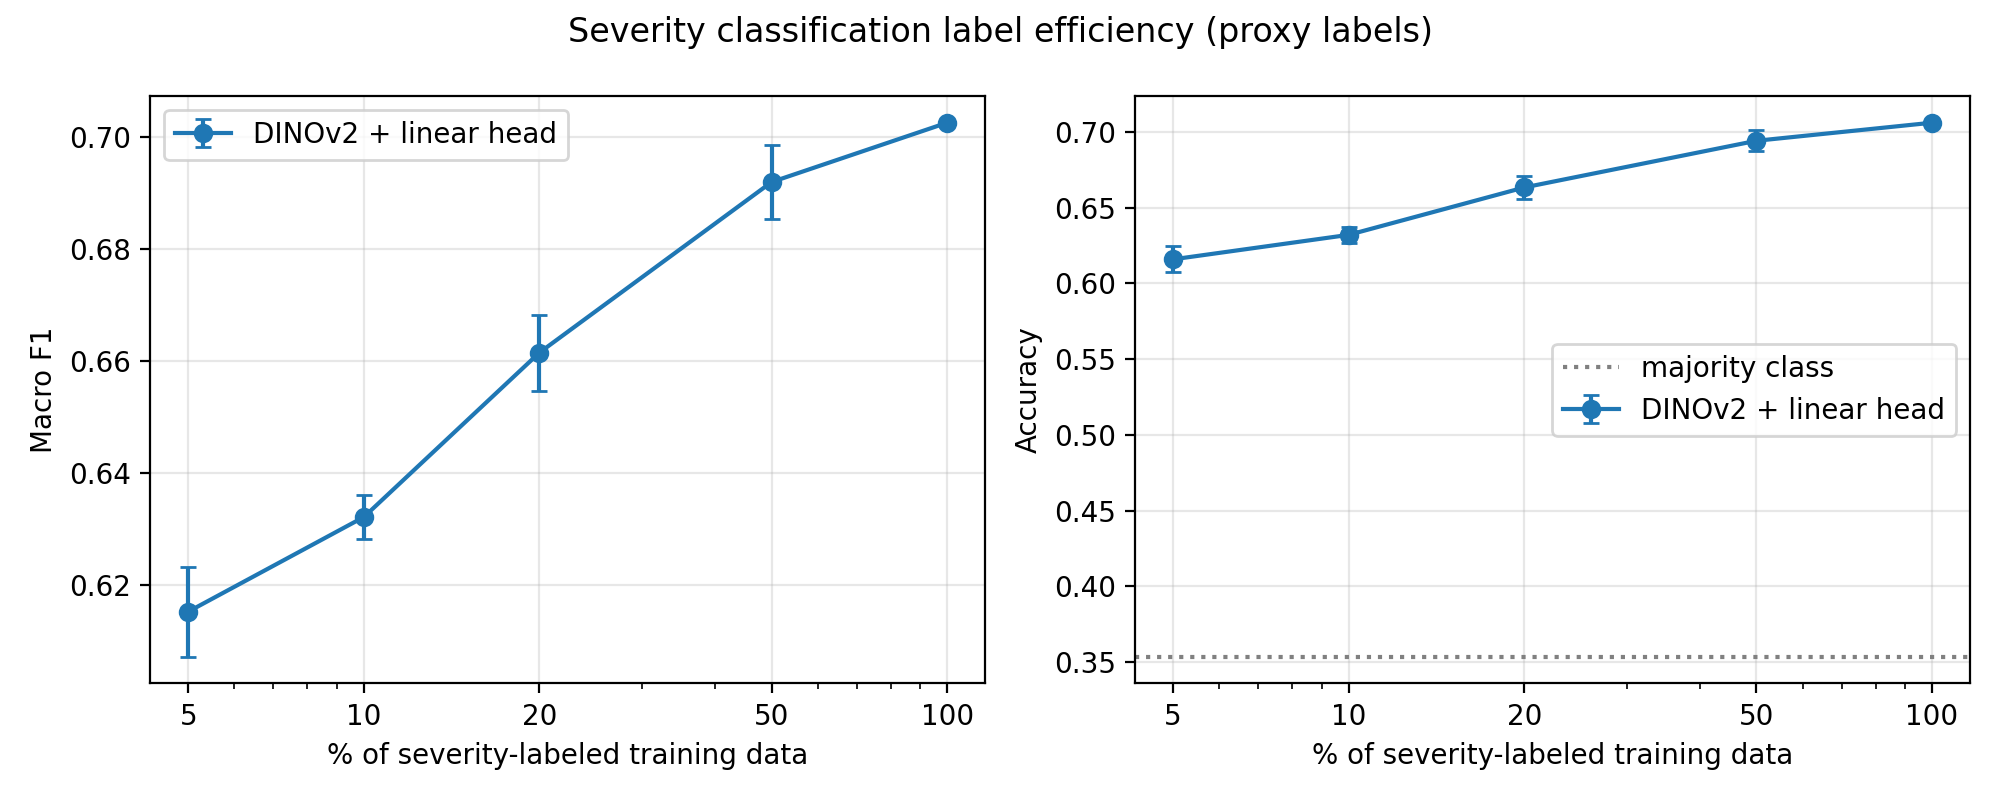

In [ ]:
from IPython.display import Image, display
display(Image("results/severity/severity_confusion_matrix.png"))
display(Image("results/severity/severity_label_efficiency.png"))

## Step 11 — Save results and models to Google Drive

In [ ]:
shutil.copytree("results/severity", f"{BACKUP}/results_severity", dirs_exist_ok=True)
shutil.copytree("severity/models", f"{BACKUP}/models", dirs_exist_ok=True)
print("Saved results and trained models to", BACKUP)

Saved results and trained models to /content/drive/MyDrive/MINI_PROJECT/outputs


## Step 12 — Try the two-stage pipeline on a few test images

In [ ]:
import pandas as pd
df = pd.read_csv("severity/severity_labels.csv")
sample = df[df.split == "test"].sample(5, random_state=0)
args = " ".join(f'"{p}"' for p in sample.path)
!python severity/infer_two_stage.py $args
print("\nAutomatic proxy labels for these images (for comparison):")
print(sample[["path", "severity_name"]].to_string(index=False))

Using cache found in /root/.cache/torch/hub/facebookresearch_dinov2_main
/root/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/swiglu_ffn.py:51: UserWarning: xFormers is not available (SwiGLU)
  warnings.warn("xFormers is not available (SwiGLU)")
/root/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/attention.py:33: UserWarning: xFormers is not available (Attention)
  warnings.warn("xFormers is not available (Attention)")
/root/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/block.py:40: UserWarning: xFormers is not available (Block)
  warnings.warn("xFormers is not available (Block)")
7075-39.jpg
  Crack detected : NO  (confidence 0.986)
7002-194.jpg
  Crack detected : NO  (confidence 0.758)
7016-204.jpg
  Crack detected : YES  (confidence 0.688)
  Severity       : MINOR  (confidence 0.87)
  Inspection priority (indicative only): LOW
7005-8.jpg
  Crack detected : NO  (confidence 0.741)
7138-153.jpg
  Crack detected : YES  (confidence 0.998)
  Severi

---
# PART 2 — Three extensions (severity validation, localization, segmentation)

Run these **after Step 12** (they need the features and severity labels from Steps 7-8, and the `BACKUP` variable from Step 3).
If Colab disconnected, first redo Steps 1-5 and run the restore cell at the very end of this notebook, then continue here.

**Read this honestly**
- Severity labels are **proxy labels** (measured crack extent), not engineering ground truth.
- SDNET2018 has no boxes or masks, so Features 2 and 3 are trained on **weak labels** generated by the crack-measurement code.
  Their scores measure agreement with that code, not with human annotation. Say so in your report.
- Everything here is a screening aid and must not be used to make repair or safety decisions.

## Cell 0 — shared helpers (photo-aware train / validation / test split)

In [ ]:
# ===== Shared helpers for the 3 extensions =====
# Needs the main notebook's Steps 1-5 (project unpacked, dataset at /content/archive)
# and Step 7 (severity/severity_labels.csv) to have been run in this session.
import os, re, zlib, json, shutil, cv2, numpy as np, pandas as pd
from severity.common import list_dataset

ARCHIVE  = "/content/archive"
EXT_ROOT = "/content/ext"                 # working folder for the extensions
os.makedirs(EXT_ROOT, exist_ok=True)
SEV_NAMES = ["Minor", "Moderate", "Severe"]

def group_key(path):
    """Patches cut from the same photo share a name prefix (e.g. 7001-12.jpg -> 7001).
    Keeping a whole photo in one split avoids train/test leakage."""
    p = path.replace("\\", "/").split("/")
    surface = p[-3] if len(p) >= 3 else ""
    return f"{surface}:{re.split(r'[-_.]', p[-1])[0]}"

def assign_split(path, test_pct=15, val_pct=15):
    """Deterministic group-aware split: ~70% train / 15% val / 15% test."""
    h = zlib.crc32(group_key(path).encode()) % 100
    return "test" if h < test_pct else ("val" if h < test_pct + val_pct else "train")

lab_all = pd.read_csv("severity/severity_labels.csv")
splits = lab_all.path.map(assign_split)
print("Cracked images per split:", splits.value_counts().to_dict())
print("Distinct source photos (groups):", lab_all.path.map(group_key).nunique())

Cracked images per split: {'train': 6094, 'test': 1487, 'val': 903}
Distinct source photos (groups): 225


## Feature 1 — Severity classification (validated, with human-review flags)
Builds on the severity head from Step 10. Uses a photo-aware train/validation/test split, chooses the
regularisation strength on the validation set only, and reports the test set once. Special attention goes to
the dangerous error "Severe predicted as Minor". Outputs are a screening aid only.

### 1A — tuned head, metrics, critical errors

train=4792  val=741  test=1252
class counts (train): [1613 1612 1567]  (test): [351 389 512]
C=0.003  validation macro-F1 = 0.7215
C=0.01   validation macro-F1 = 0.7250
C=0.03   validation macro-F1 = 0.7175
C=0.1    validation macro-F1 = 0.7121
C=0.3    validation macro-F1 = 0.7150
C=1.0    validation macro-F1 = 0.7086
Chosen C (by validation): 0.01

=== TEST RESULTS (frozen DINOv2 + linear head) ===
              precision    recall  f1-score   support

       Minor      0.759     0.746     0.753       351
    Moderate      0.580     0.524     0.551       389
      Severe      0.773     0.838     0.804       512

    accuracy                          0.715      1252
   macro avg      0.704     0.703     0.703      1252
weighted avg      0.709     0.715     0.711      1252

Macro-F1: 0.7025

CRITICAL ERROR  Severe predicted as Minor   : 3 of 512 (0.6%)
                Severe predicted as Moderate: 80 of 512 (15.6%)


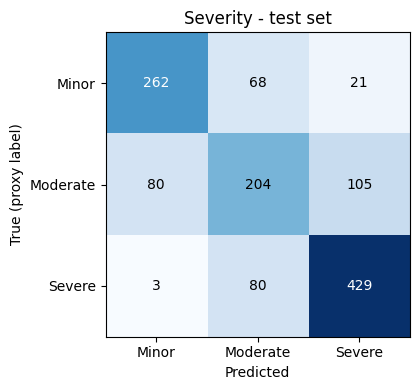

['severity/models/severity_head_tuned.joblib']

In [ ]:
# ===== Feature 1A: severity head with a proper validation split, tuned C, critical-error report =====
import joblib
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix, f1_score

d = np.load("severity/features_dinov2_vits14.npz")
lab = lab_all[lab_all.severity >= 0].reset_index(drop=True)
assert (d["paths"][lab.idx.values] == lab.path.values).all(), "feature file and label file do not match"
X, y = d["features"][lab.idx.values], lab.severity.values.astype(int)
sp = lab.path.map(assign_split).values
tr, va, te = [np.where(sp == s)[0] for s in ("train", "val", "test")]
print(f"train={len(tr)}  val={len(va)}  test={len(te)}")
print("class counts (train):", np.bincount(y[tr], minlength=3), " (test):", np.bincount(y[te], minlength=3))

def fit_head(Xtr, ytr, C):
    sc = StandardScaler().fit(Xtr)
    clf = LogisticRegression(C=C, max_iter=3000, class_weight="balanced").fit(sc.transform(Xtr), ytr)
    return sc, clf

best = (-1, None)
for C in [0.003, 0.01, 0.03, 0.1, 0.3, 1.0]:
    sc, clf = fit_head(X[tr], y[tr], C)
    f1 = f1_score(y[va], clf.predict(sc.transform(X[va])), labels=[0, 1, 2], average="macro", zero_division=0)
    print(f"C={C:<6} validation macro-F1 = {f1:.4f}")
    if f1 > best[0]:
        best = (f1, C)
C_BEST = best[1]
print("Chosen C (by validation):", C_BEST)

sc, clf = fit_head(X[tr], y[tr], C_BEST)          # test set is touched only now
proba = clf.predict_proba(sc.transform(X[te]))
pred, yt = clf.classes_[proba.argmax(1)], y[te]

print("\n=== TEST RESULTS (frozen DINOv2 + linear head) ===")
print(classification_report(yt, pred, labels=[0, 1, 2], target_names=SEV_NAMES, digits=3, zero_division=0))
FROZEN_MACRO_F1 = f1_score(yt, pred, labels=[0, 1, 2], average="macro", zero_division=0)
print("Macro-F1:", round(FROZEN_MACRO_F1, 4))

cm = confusion_matrix(yt, pred, labels=[0, 1, 2])
n_sev = max(cm[2].sum(), 1)
print(f"\nCRITICAL ERROR  Severe predicted as Minor   : {cm[2,0]} of {cm[2].sum()} ({100*cm[2,0]/n_sev:.1f}%)")
print(f"                Severe predicted as Moderate: {cm[2,1]} of {cm[2].sum()} ({100*cm[2,1]/n_sev:.1f}%)")

fig, ax = plt.subplots(figsize=(4.6, 4))
ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(3)); ax.set_xticklabels(SEV_NAMES); ax.set_yticks(range(3)); ax.set_yticklabels(SEV_NAMES)
ax.set_xlabel("Predicted"); ax.set_ylabel("True (proxy label)"); ax.set_title("Severity - test set")
for i in range(3):
    for j in range(3):
        ax.text(j, i, cm[i, j], ha="center", va="center", color="white" if cm[i, j] > cm.max() / 2 else "black")
plt.tight_layout(); plt.show()

os.makedirs("severity/models", exist_ok=True)
joblib.dump({"scaler": sc, "clf": clf, "classes": SEV_NAMES, "C": C_BEST}, "severity/models/severity_head_tuned.joblib")

### 1B — low-confidence cases go to a human

In [ ]:
# ===== Feature 1B: flag low-confidence predictions for human review =====
conf = proba.max(1)
rows = []
for t in [0.0, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]:
    keep = conf >= t
    n = int(keep.sum())
    rows.append({
        "min_confidence": t,
        "auto_accepted_%": round(100 * n / len(conf), 1),
        "sent_to_human_%": round(100 * (1 - n / len(conf)), 1),
        "accuracy_on_accepted": round(float((pred[keep] == yt[keep]).mean()), 3) if n else None,
        "Severe->Minor_still_accepted": int(((yt == 2) & (pred == 0) & keep).sum()),
    })
print(pd.DataFrame(rows).to_string(index=False))

REVIEW_THRESHOLD = 0.6      # choose from the table above: fewer silent mistakes vs more manual review
print(f"\nWith threshold {REVIEW_THRESHOLD}, any prediction below it is marked 'NEEDS HUMAN REVIEW'.")
print("Low confidence must never be treated as 'safe' or as 'dangerous' - it only means 'a person should look'.")

 min_confidence  auto_accepted_%  sent_to_human_%  accuracy_on_accepted  Severe->Minor_still_accepted
            0.0            100.0              0.0                 0.715                             3
            0.4             99.4              0.6                 0.719                             3
            0.5             89.5             10.5                 0.742                             1
            0.6             69.9             30.1                 0.809                             1
            0.7             51.0             49.0                 0.873                             1
            0.8             33.9             66.1                 0.936                             1
            0.9             17.3             82.7                 0.968                             0

With threshold 0.6, any prediction below it is marked 'NEEDS HUMAN REVIEW'.
Low confidence must never be treated as 'safe' or as 'dangerous' - it only means 'a person should look'.


### 1C — OPTIONAL: fine-tune the last DINOv2 blocks and compare fairly (GPU)

In [ ]:
# ===== Feature 1C (OPTIONAL): fine-tune the last DINOv2 blocks and compare fairly with the frozen result =====
# Run only after 1A works. Uses the same train / val / test split as 1A.
import copy, torch, torch.nn as nn
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

dev = "cuda"
EPOCHS, N_UNFREEZE, BATCH = 5, 2, 32
norm = transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
tf_train = transforms.Compose([transforms.Resize((224, 224)), transforms.RandomHorizontalFlip(),
                               transforms.RandomVerticalFlip(), transforms.ColorJitter(0.2, 0.2),
                               transforms.ToTensor(), norm])
tf_eval = transforms.Compose([transforms.Resize((224, 224)), transforms.ToTensor(), norm])

class SevDS(Dataset):
    def __init__(self, idx, tf):
        self.p, self.y, self.tf = lab.path.values[idx], y[idx], tf
    def __len__(self):
        return len(self.p)
    def __getitem__(self, i):
        return self.tf(Image.open(self.p[i]).convert("RGB")), int(self.y[i])

dl_tr = DataLoader(SevDS(tr, tf_train), batch_size=BATCH, shuffle=True, num_workers=2, drop_last=True)
dl_va = DataLoader(SevDS(va, tf_eval), batch_size=64, num_workers=2)
dl_te = DataLoader(SevDS(te, tf_eval), batch_size=64, num_workers=2)

torch.manual_seed(0)
backbone = torch.hub.load("facebookresearch/dinov2", "dinov2_vits14").to(dev)
for p in backbone.parameters():
    p.requires_grad = False
for blk in backbone.blocks[-N_UNFREEZE:]:
    for p in blk.parameters():
        p.requires_grad = True
for p in backbone.norm.parameters():
    p.requires_grad = True
head = nn.Linear(384, 3).to(dev)

cnt = np.bincount(y[tr], minlength=3).astype(float)
w = torch.tensor(len(tr) / (3 * np.maximum(cnt, 1)), dtype=torch.float32, device=dev)
loss_fn = nn.CrossEntropyLoss(weight=w)
opt = torch.optim.AdamW([
    {"params": [p for p in backbone.parameters() if p.requires_grad], "lr": 1e-5},
    {"params": head.parameters(), "lr": 1e-3}], weight_decay=1e-4)
scaler_amp = torch.amp.GradScaler("cuda")

@torch.no_grad()
def predict(loader):
    backbone.eval(); head.eval()
    P, T = [], []
    for xb, yb in loader:
        with torch.autocast("cuda", dtype=torch.float16):
            lo = head(backbone(xb.to(dev)))
        P.append(torch.softmax(lo.float(), 1).cpu().numpy()); T.append(yb.numpy())
    return np.concatenate(P), np.concatenate(T)

best_f1, best_state = -1, None
for ep in range(EPOCHS):
    backbone.train(); head.train()
    tot = 0.0
    for xb, yb in dl_tr:
        xb, yb = xb.to(dev), yb.to(dev)
        opt.zero_grad(set_to_none=True)
        with torch.autocast("cuda", dtype=torch.float16):
            lo = head(backbone(xb))
        loss = loss_fn(lo.float(), yb)
        scaler_amp.scale(loss).backward(); scaler_amp.step(opt); scaler_amp.update()
        tot += loss.item()
    pv, tv = predict(dl_va)
    f1v = f1_score(tv, pv.argmax(1), labels=[0, 1, 2], average="macro", zero_division=0)
    print(f"epoch {ep+1}/{EPOCHS}  train loss {tot/len(dl_tr):.4f}  val macro-F1 {f1v:.4f}")
    if f1v > best_f1:
        best_f1 = f1v
        best_state = (copy.deepcopy(backbone.state_dict()), copy.deepcopy(head.state_dict()))

backbone.load_state_dict(best_state[0]); head.load_state_dict(best_state[1])
pt, tt = predict(dl_te)
pt_lab = pt.argmax(1)
ft_f1 = f1_score(tt, pt_lab, labels=[0, 1, 2], average="macro", zero_division=0)
print("\n=== TEST RESULTS (partially fine-tuned DINOv2) ===")
print(classification_report(tt, pt_lab, labels=[0, 1, 2], target_names=SEV_NAMES, digits=3, zero_division=0))
cm_ft = confusion_matrix(tt, pt_lab, labels=[0, 1, 2])
print("Severe predicted as Minor:", cm_ft[2, 0], "of", cm_ft[2].sum())
print(f"\nFAIR COMPARISON (same split, same test images)\n  frozen encoder   : macro-F1 {FROZEN_MACRO_F1:.4f}\n  fine-tuned ({N_UNFREEZE} blocks): macro-F1 {ft_f1:.4f}")
torch.save({"backbone": best_state[0], "head": best_state[1], "classes": SEV_NAMES}, f"{EXT_ROOT}/severity_finetuned.pt")

Using cache found in /root/.cache/torch/hub/facebookresearch_dinov2_main
/root/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/swiglu_ffn.py:51: UserWarning: xFormers is not available (SwiGLU)
  warnings.warn("xFormers is not available (SwiGLU)")
/root/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/attention.py:33: UserWarning: xFormers is not available (Attention)
  warnings.warn("xFormers is not available (Attention)")
/root/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/block.py:40: UserWarning: xFormers is not available (Block)
  warnings.warn("xFormers is not available (Block)")


epoch 1/5  train loss 0.8211  val macro-F1 0.7057
epoch 2/5  train loss 0.6532  val macro-F1 0.7432
epoch 3/5  train loss 0.5853  val macro-F1 0.6922
epoch 4/5  train loss 0.5503  val macro-F1 0.7579
epoch 5/5  train loss 0.5052  val macro-F1 0.7777

=== TEST RESULTS (partially fine-tuned DINOv2) ===
              precision    recall  f1-score   support

       Minor      0.829     0.775     0.801       351
    Moderate      0.662     0.656     0.659       389
      Severe      0.822     0.865     0.843       512

    accuracy                          0.775      1252
   macro avg      0.771     0.765     0.768      1252
weighted avg      0.774     0.775     0.774      1252

Severe predicted as Minor: 4 of 512

FAIR COMPARISON (same split, same test images)
  frozen encoder   : macro-F1 0.7025
  fine-tuned (2 blocks): macro-F1 0.7677


## Weak labels for localization and segmentation (needed by Features 2 and 3)
Boxes (YOLO format) and masks are generated automatically by the crack-measurement code. A share of uncracked
images (empty labels) is added so the models also learn "no crack -> no output". Splits keep all patches of one
photo together. **Look at the preview:** if the masks do not follow real cracks, the downstream results are meaningless.

Weak labels:   0%|          | 0/8481 [00:00<?, ?it/s]


Images per split (crack / no-crack):
is_crack  False  True 
split                 
test        298   1252
train      1200   4792
val         198    741
Mean boxes per cracked image: 2.51


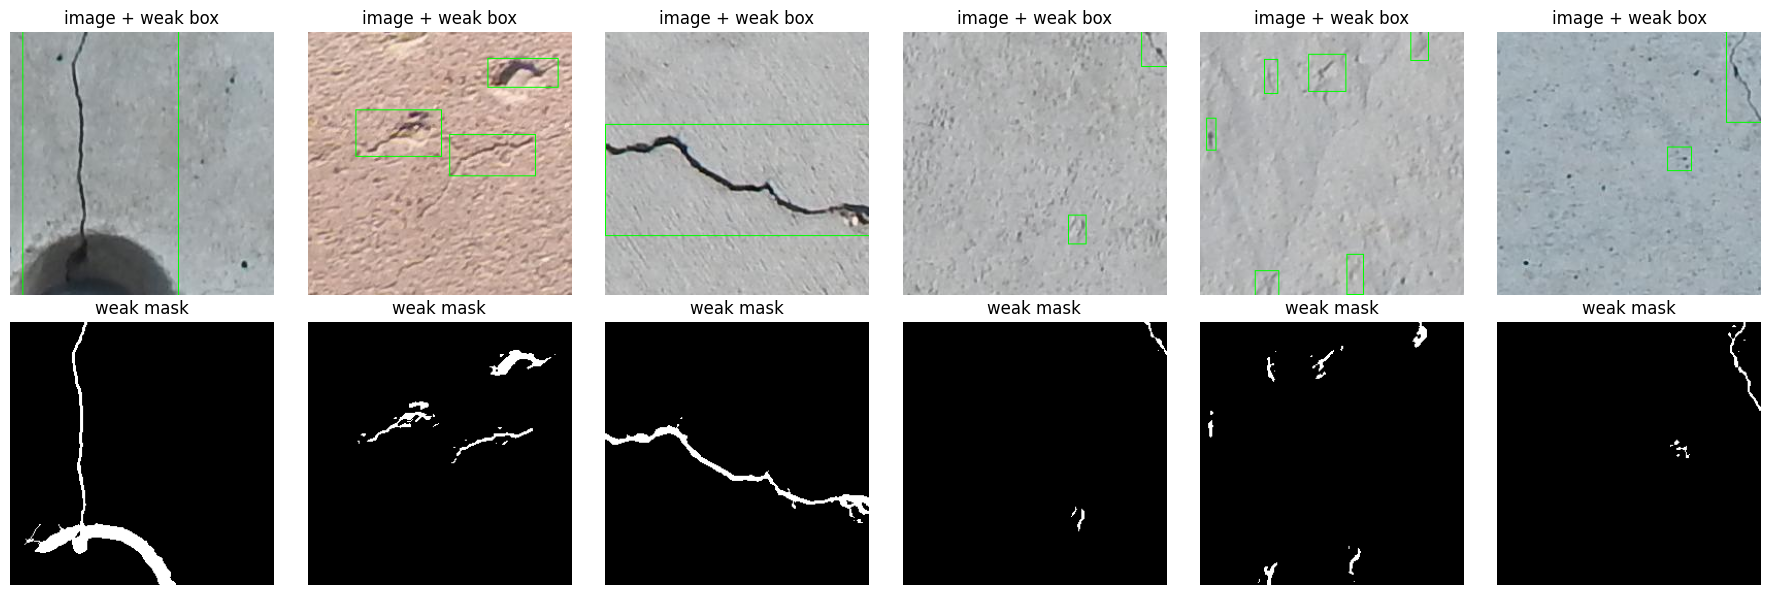

In [ ]:
# ===== Build WEAK labels (boxes + masks) from the crack-measurement code =====
import cv2, shutil, random
from multiprocessing import Pool
from tqdm.auto import tqdm
from severity.measure_cracks import measure_crack

WEAK = f"{EXT_ROOT}/weak"
N_NEG_RATIO = 0.25      # uncracked images added per cracked image (teaches "no crack -> empty output")
MIN_BOX = 6             # ignore boxes smaller than this (pixels) in both directions

def boxes_from_mask(mask, merge_px=15, pad=2):
    """One box per group of nearby crack fragments."""
    m = (mask > 0).astype(np.uint8)
    k = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (merge_px, merge_px))
    n, comp = cv2.connectedComponents(cv2.dilate(m, k), connectivity=8)
    H, W = m.shape
    out = []
    for l in range(1, n):
        ys, xs = np.where((comp == l) & (m > 0))
        if len(xs) == 0:
            continue
        x0, x1 = max(xs.min() - pad, 0), min(xs.max() + 1 + pad, W)
        y0, y1 = max(ys.min() - pad, 0), min(ys.max() + 1 + pad, H)
        if (x1 - x0) >= MIN_BOX or (y1 - y0) >= MIN_BOX:
            out.append((int(x0), int(y0), int(x1), int(y1)))
    return out

def _build_one(job):
    src, stem, split, is_pos = job
    img = cv2.imread(src)
    if img is None:
        return (stem, split, -1)
    H, W = img.shape[:2]
    mask, boxes = np.zeros((H, W), np.uint8), []
    if is_pos:
        _, m, _ = measure_crack(img, return_masks=True)
        mask = m.astype(np.uint8) * 255
        boxes = boxes_from_mask(mask)
        if not boxes:                      # nothing usable measured -> skip this image
            return (stem, split, -1)
    shutil.copy(src, f"{WEAK}/images/{split}/{stem}{os.path.splitext(src)[1]}")
    cv2.imwrite(f"{WEAK}/masks/{split}/{stem}.png", mask)
    with open(f"{WEAK}/labels/{split}/{stem}.txt", "w") as f:       # YOLO format, class 0 = crack
        for x0, y0, x1, y1 in boxes:
            f.write(f"0 {(x0+x1)/2/W:.6f} {(y0+y1)/2/H:.6f} {(x1-x0)/W:.6f} {(y1-y0)/H:.6f}\n")
    return (stem, split, len(boxes))

# --- choose images
paths, targets, surfaces = list_dataset(ARCHIVE)
pos = lab_all[lab_all.length_px > 0]
jobs = [(r.path, f"p{r.idx:06d}", assign_split(r.path), True) for r in pos.itertuples()]
neg_idx = np.where(targets == 1)[0]
rng = np.random.RandomState(0)
neg_idx = rng.choice(neg_idx, size=int(N_NEG_RATIO * len(jobs)), replace=False)
jobs += [(paths[i], f"n{i:06d}", assign_split(paths[i]), False) for i in neg_idx]

# --- build folders
shutil.rmtree(WEAK, ignore_errors=True)
for sub in ("images", "masks", "labels"):
    for sp in ("train", "val", "test"):
        os.makedirs(f"{WEAK}/{sub}/{sp}", exist_ok=True)

with Pool(2) as pool:
    res = list(tqdm(pool.imap_unordered(_build_one, jobs, chunksize=32), total=len(jobs), desc="Weak labels"))

man = pd.DataFrame(res, columns=["stem", "split", "n_boxes"])
man = man[man.n_boxes >= 0]
man["is_crack"] = man.stem.str.startswith("p")
man.to_csv(f"{WEAK}/manifest.csv", index=False)
print("\nImages per split (crack / no-crack):")
print(man.groupby(["split", "is_crack"]).size().unstack(fill_value=0))
print("Mean boxes per cracked image:", round(man[man.is_crack].n_boxes.mean(), 2))

# --- LOOK AT THESE: weak labels are only as good as the measurement code
import matplotlib.pyplot as plt
ex = man[(man.is_crack) & (man.split == "train")].sample(6, random_state=1)
fig, axes = plt.subplots(2, 6, figsize=(18, 6))
for j, s in enumerate(ex.stem):
    f = [x for x in os.listdir(f"{WEAK}/images/train") if x.startswith(s)][0]
    im = cv2.cvtColor(cv2.imread(f"{WEAK}/images/train/{f}"), cv2.COLOR_BGR2RGB)
    mk = cv2.imread(f"{WEAK}/masks/train/{s}.png", 0)
    H, W = mk.shape
    for line in open(f"{WEAK}/labels/train/{s}.txt"):
        _, cx, cy, bw, bh = map(float, line.split())
        cv2.rectangle(im, (int((cx-bw/2)*W), int((cy-bh/2)*H)), (int((cx+bw/2)*W), int((cy+bh/2)*H)), (0, 255, 0), 1)
    axes[0, j].imshow(im); axes[0, j].set_title("image + weak box"); axes[0, j].axis("off")
    axes[1, j].imshow(mk, cmap="gray"); axes[1, j].set_title("weak mask"); axes[1, j].axis("off")
plt.tight_layout(); plt.show()

## Feature 2 — Crack localization with YOLO
Boxes are WEAK labels, so metrics show agreement with those boxes, not with human annotation. Boxes show approximate
location only; they do not measure crack width or establish severity.

### 2A — install

In [ ]:
!pip install -q ultralytics

### 2B — train

In [ ]:
# ===== Feature 2: crack LOCALIZATION with YOLO (trained on weak boxes) =====
import yaml
from ultralytics import YOLO
os.environ["WANDB_DISABLED"] = "true"

yaml.safe_dump({"path": WEAK, "train": "images/train", "val": "images/val", "test": "images/test",
                "names": {0: "crack"}}, open(f"{WEAK}/data.yaml", "w"))

try:
    det = YOLO("yolo11n.pt")
except Exception:
    det = YOLO("yolov8n.pt")          # fallback if the newer weights are unavailable

det.train(data=f"{WEAK}/data.yaml", epochs=30, imgsz=256, batch=32, workers=2, device=0,
          project=f"{EXT_ROOT}/yolo_runs", name="crack_det", exist_ok=True,
          patience=10, plots=True, verbose=False)

BEST_YOLO = os.path.join(str(det.trainer.save_dir), "weights", "best.pt")
print("Best weights:", BEST_YOLO)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Ultralytics 8.4.194 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=32, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/ext/weak/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, fre

### 2C — evaluate on the test split and inspect predictions

Ultralytics 8.4.194 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 101 layers, 2,597,051 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 241.5±93.3 MB/s, size: 8.0 KB)
val: Scanning /content/ext/weak/labels/test... 1550 images, 298 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1550/1550 1.8Kit/s 0.9s
val: New cache created: /content/ext/weak/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 49/49 3.3it/s 14.9s
                   all       1550       3097      0.602      0.626      0.643      0.388
Speed: 0.5ms preprocess, 1.7ms inference, 0.0ms loss, 2.2ms postprocess per image
Results saved to /content/project/SSL-For-Bridge-Crack-Classification-main/runs/detect/val

=== Box metrics on TEST (agreement with the WEAK boxes) ===
precision 0.602 | recall 0.626 | mAP@0.5 0.643 | mAP@0.5:0.95 0.388

Image-level 'crack present' (conf>=0.25): 

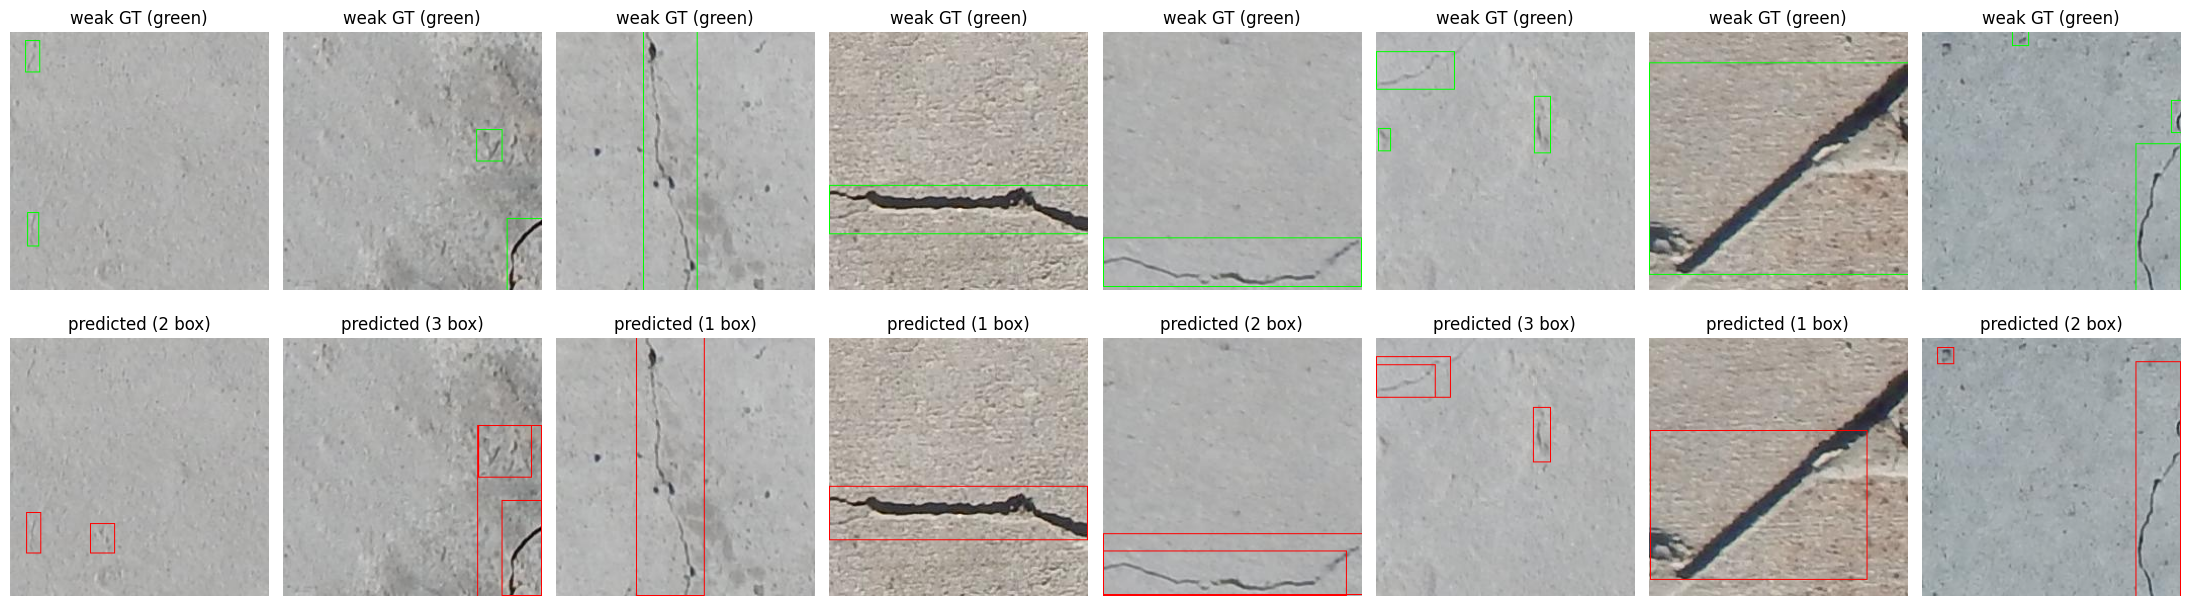

In [ ]:
# ===== Feature 2: evaluate on the held-out TEST split =====
from sklearn.metrics import precision_recall_fscore_support
import matplotlib.pyplot as plt

det = YOLO(BEST_YOLO)
m = det.val(data=f"{WEAK}/data.yaml", split="test", imgsz=256, batch=32, device=0, verbose=False)
print("\n=== Box metrics on TEST (agreement with the WEAK boxes) ===")
print(f"precision {m.box.mp:.3f} | recall {m.box.mr:.3f} | mAP@0.5 {m.box.map50:.3f} | mAP@0.5:0.95 {m.box.map:.3f}")

# image-level view: does the detector find *a* crack in cracked images and stay silent on uncracked ones?
man = pd.read_csv(f"{WEAK}/manifest.csv")
te_man = man[man.split == "test"].reset_index(drop=True)
files = [f"{WEAK}/images/test/" + [x for x in os.listdir(f"{WEAK}/images/test") if x.startswith(s)][0] for s in te_man.stem]
CONF = 0.25
pred_has = []
for r in det.predict(source=files, conf=CONF, imgsz=256, stream=True, verbose=False):
    pred_has.append(len(r.boxes) > 0)
p, r_, f, _ = precision_recall_fscore_support(te_man.is_crack.astype(int).values, np.array(pred_has).astype(int), average="binary", zero_division=0)
print(f"\nImage-level 'crack present' (conf>={CONF}): precision {p:.3f} | recall {r_:.3f} | F1 {f:.3f}")

# visual check: weak ground truth (green) vs prediction (red). Look at failures too!
def draw(im, boxes, color):
    for (x0, y0, x1, y1) in boxes:
        cv2.rectangle(im, (int(x0), int(y0)), (int(x1), int(y1)), color, 1)
    return im

sel = te_man[te_man.is_crack].sample(min(8, int(te_man.is_crack.sum())), random_state=0)
fig, axes = plt.subplots(2, 8, figsize=(22, 6.5))
for j, s in enumerate(sel.stem):
    fp = f"{WEAK}/images/test/" + [x for x in os.listdir(f"{WEAK}/images/test") if x.startswith(s)][0]
    im = cv2.cvtColor(cv2.imread(fp), cv2.COLOR_BGR2RGB); H, W = im.shape[:2]
    gt = []
    for line in open(f"{WEAK}/labels/test/{s}.txt"):
        _, cx, cy, bw, bh = map(float, line.split())
        gt.append(((cx-bw/2)*W, (cy-bh/2)*H, (cx+bw/2)*W, (cy+bh/2)*H))
    res = det.predict(source=fp, conf=CONF, imgsz=256, verbose=False)[0]
    pb = res.boxes.xyxy.cpu().numpy().tolist()
    axes[0, j].imshow(draw(im.copy(), gt, (0, 255, 0))); axes[0, j].set_title("weak GT (green)"); axes[0, j].axis("off")
    axes[1, j].imshow(draw(im.copy(), pb, (255, 0, 0))); axes[1, j].set_title(f"predicted ({len(pb)} box)"); axes[1, j].axis("off")
plt.tight_layout(); plt.show()

### 2D — save to Drive

In [ ]:
# ===== Feature 2: save to Google Drive =====
out = f"{BACKUP}/localization"
os.makedirs(out, exist_ok=True)
shutil.copy(BEST_YOLO, f"{out}/crack_yolo_best.pt")
shutil.copy(f"{WEAK}/data.yaml", out)
shutil.copy(f"{WEAK}/manifest.csv", out)

# Safely copy results.csv if det.trainer is present
run_dir = None
if hasattr(det, 'trainer') and det.trainer is not None:
    run_dir = str(det.trainer.save_dir)
elif os.path.exists(f"{EXT_ROOT}/yolo_runs/crack_det"):
    run_dir = f"{EXT_ROOT}/yolo_runs/crack_det"

if run_dir and os.path.exists(os.path.join(run_dir, "results.csv")):
    shutil.copy(os.path.join(run_dir, "results.csv"), out)
    print("Saved training curves (results.csv) to", out)

print("Saved to", out)

Saved training curves (results.csv) to /content/drive/MyDrive/MINI_PROJECT/outputs/localization
Saved to /content/drive/MyDrive/MINI_PROJECT/outputs/localization


## Feature 3 — Crack segmentation with a U-Net
A plain-PyTorch U-Net trained with BCE + Dice loss. The threshold is chosen on the VALIDATION split only; IoU, Dice,
precision and recall are reported on the held-out TEST split. Masks are WEAK labels. No physical crack width or length
is reported because the images have no validated scale calibration.

### 3A — data, model, loss, metrics

In [ ]:
# ===== Feature 3: crack SEGMENTATION with a U-Net (trained on weak masks) =====
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import matplotlib.pyplot as plt

dev, IMG = "cuda", 256
torch.manual_seed(0); np.random.seed(0)

class SegDS(Dataset):
    def __init__(self, split, augment=False):
        self.split, self.augment = split, augment
        self.files = sorted(os.listdir(f"{WEAK}/images/{split}"))
    def __len__(self):
        return len(self.files)
    def __getitem__(self, i):
        f = self.files[i]
        img = cv2.cvtColor(cv2.imread(f"{WEAK}/images/{self.split}/{f}"), cv2.COLOR_BGR2RGB)
        msk = cv2.imread(f"{WEAK}/masks/{self.split}/{os.path.splitext(f)[0]}.png", 0)
        img = cv2.resize(img, (IMG, IMG), interpolation=cv2.INTER_LINEAR)
        msk = cv2.resize(msk, (IMG, IMG), interpolation=cv2.INTER_NEAREST)
        if self.augment:                                   # identical geometry for image and mask
            if np.random.rand() < 0.5: img, msk = img[:, ::-1], msk[:, ::-1]
            if np.random.rand() < 0.5: img, msk = img[::-1], msk[::-1]
            k = np.random.randint(4); img, msk = np.rot90(img, k), np.rot90(msk, k)
        x = torch.from_numpy(np.ascontiguousarray(img.transpose(2, 0, 1))).float() / 255.0
        x = (x - 0.5) / 0.5
        y = torch.from_numpy(np.ascontiguousarray((msk > 127).astype(np.float32)))[None]
        return x, y

def block(i, o):
    return nn.Sequential(nn.Conv2d(i, o, 3, padding=1, bias=False), nn.BatchNorm2d(o), nn.ReLU(True),
                         nn.Conv2d(o, o, 3, padding=1, bias=False), nn.BatchNorm2d(o), nn.ReLU(True))

class UNet(nn.Module):
    def __init__(self, c=32):
        super().__init__()
        self.e1, self.e2, self.e3, self.e4 = block(3, c), block(c, 2*c), block(2*c, 4*c), block(4*c, 8*c)
        self.b = block(8*c, 16*c)
        self.u4, self.d4 = nn.ConvTranspose2d(16*c, 8*c, 2, 2), block(16*c, 8*c)
        self.u3, self.d3 = nn.ConvTranspose2d(8*c, 4*c, 2, 2), block(8*c, 4*c)
        self.u2, self.d2 = nn.ConvTranspose2d(4*c, 2*c, 2, 2), block(4*c, 2*c)
        self.u1, self.d1 = nn.ConvTranspose2d(2*c, c, 2, 2), block(2*c, c)
        self.out = nn.Conv2d(c, 1, 1)
    def forward(self, x):
        e1 = self.e1(x); e2 = self.e2(F.max_pool2d(e1, 2)); e3 = self.e3(F.max_pool2d(e2, 2))
        e4 = self.e4(F.max_pool2d(e3, 2)); b = self.b(F.max_pool2d(e4, 2))
        d4 = self.d4(torch.cat([self.u4(b), e4], 1)); d3 = self.d3(torch.cat([self.u3(d4), e3], 1))
        d2 = self.d2(torch.cat([self.u2(d3), e2], 1)); d1 = self.d1(torch.cat([self.u1(d2), e1], 1))
        return self.out(d1)

def seg_loss(logits, y):                 # binary cross-entropy + Dice (computed over the whole batch)
    bce = F.binary_cross_entropy_with_logits(logits, y)
    p = torch.sigmoid(logits)
    dice = 1 - (2 * (p * y).sum() + 1) / (p.sum() + y.sum() + 1)
    return bce + dice

@torch.no_grad()
def eval_counts(model, loader, thrs):
    """Pixel-level TP/FP/FN/TN for each threshold, accumulated over a loader."""
    model.eval()
    c = {t: np.zeros(4) for t in thrs}
    for x, y in loader:
        p = torch.sigmoid(model(x.to(dev)).float()); y = y.to(dev) > 0.5
        for t in thrs:
            pb = p > t
            tp = (pb & y).sum().item(); fp = (pb & ~y).sum().item(); fn = (~pb & y).sum().item()
            c[t] += [tp, fp, fn, y.numel() - tp - fp - fn]
    return c

def seg_metrics(c):
    tp, fp, fn, _ = c
    return {"IoU": tp / max(tp + fp + fn, 1), "Dice": 2 * tp / max(2 * tp + fp + fn, 1),
            "precision": tp / max(tp + fp, 1), "recall": tp / max(tp + fn, 1)}

dl_tr = DataLoader(SegDS("train", True), batch_size=16, shuffle=True, num_workers=2, drop_last=True, pin_memory=True)
dl_va = DataLoader(SegDS("val"), batch_size=32, num_workers=2)
dl_te = DataLoader(SegDS("test"), batch_size=32, num_workers=2)
print("train / val / test images:", len(dl_tr.dataset), len(dl_va.dataset), len(dl_te.dataset))

train / val / test images: 5992 939 1550


### 3B — train

epoch  1/15  loss 1.4479  val Dice 0.4082  val IoU 0.2564
epoch  2/15  loss 1.0466  val Dice 0.5601  val IoU 0.3890
epoch  3/15  loss 0.4837  val Dice 0.6382  val IoU 0.4687
epoch  4/15  loss 0.3957  val Dice 0.5999  val IoU 0.4285
epoch  5/15  loss 0.3604  val Dice 0.7012  val IoU 0.5398
epoch  6/15  loss 0.3473  val Dice 0.6544  val IoU 0.4863
epoch  7/15  loss 0.3449  val Dice 0.6913  val IoU 0.5282
epoch  8/15  loss 0.3315  val Dice 0.6831  val IoU 0.5187
epoch  9/15  loss 0.3209  val Dice 0.7091  val IoU 0.5493
epoch 10/15  loss 0.3141  val Dice 0.7291  val IoU 0.5737
epoch 11/15  loss 0.3020  val Dice 0.7306  val IoU 0.5755
epoch 12/15  loss 0.2954  val Dice 0.7376  val IoU 0.5842
epoch 13/15  loss 0.2862  val Dice 0.7446  val IoU 0.5931
epoch 14/15  loss 0.2794  val Dice 0.7422  val IoU 0.5901
epoch 15/15  loss 0.2780  val Dice 0.7428  val IoU 0.5908


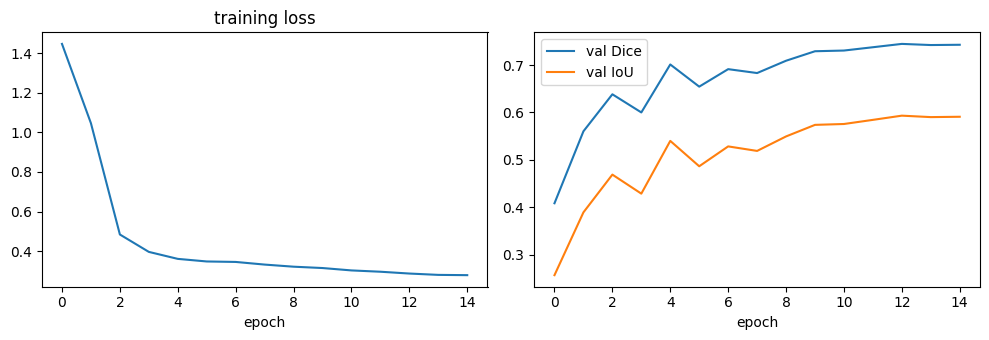

In [ ]:
# ===== Feature 3: train =====
EPOCHS = 15
model = UNet(32).to(dev)
opt = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)
sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=2e-3, total_steps=EPOCHS * len(dl_tr))
scaler_amp = torch.amp.GradScaler("cuda")
hist, best_dice, best_w = [], -1, None

for ep in range(EPOCHS):
    model.train(); tot = 0.0
    for x, y in dl_tr:
        x, y = x.to(dev, non_blocking=True), y.to(dev, non_blocking=True)
        opt.zero_grad(set_to_none=True)
        with torch.autocast("cuda", dtype=torch.float16):
            logits = model(x)
        loss = seg_loss(logits.float(), y)
        scaler_amp.scale(loss).backward(); scaler_amp.step(opt); scaler_amp.update(); sched.step()
        tot += loss.item()
    vm = seg_metrics(eval_counts(model, dl_va, [0.5])[0.5])
    hist.append((tot / len(dl_tr), vm["Dice"], vm["IoU"]))
    print(f"epoch {ep+1:>2}/{EPOCHS}  loss {hist[-1][0]:.4f}  val Dice {vm['Dice']:.4f}  val IoU {vm['IoU']:.4f}")
    if vm["Dice"] > best_dice:
        best_dice = vm["Dice"]; best_w = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}

model.load_state_dict(best_w)
h = np.array(hist)
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].plot(h[:, 0]); ax[0].set_title("training loss"); ax[0].set_xlabel("epoch")
ax[1].plot(h[:, 1], label="val Dice"); ax[1].plot(h[:, 2], label="val IoU"); ax[1].legend(); ax[1].set_xlabel("epoch")
plt.tight_layout(); plt.show()

### 3C — threshold on validation, report on test, overlays

Threshold chosen on validation data: 0.3

=== TEST RESULTS (agreement with the WEAK masks) ===
{'IoU': np.float64(0.643), 'Dice': np.float64(0.7827), 'precision': np.float64(0.7841), 'recall': np.float64(0.7813)}
Cracked test images: mean Dice 0.721 | median 0.803
Uncracked test images with >50 predicted crack pixels (false alarms): 126 of 298


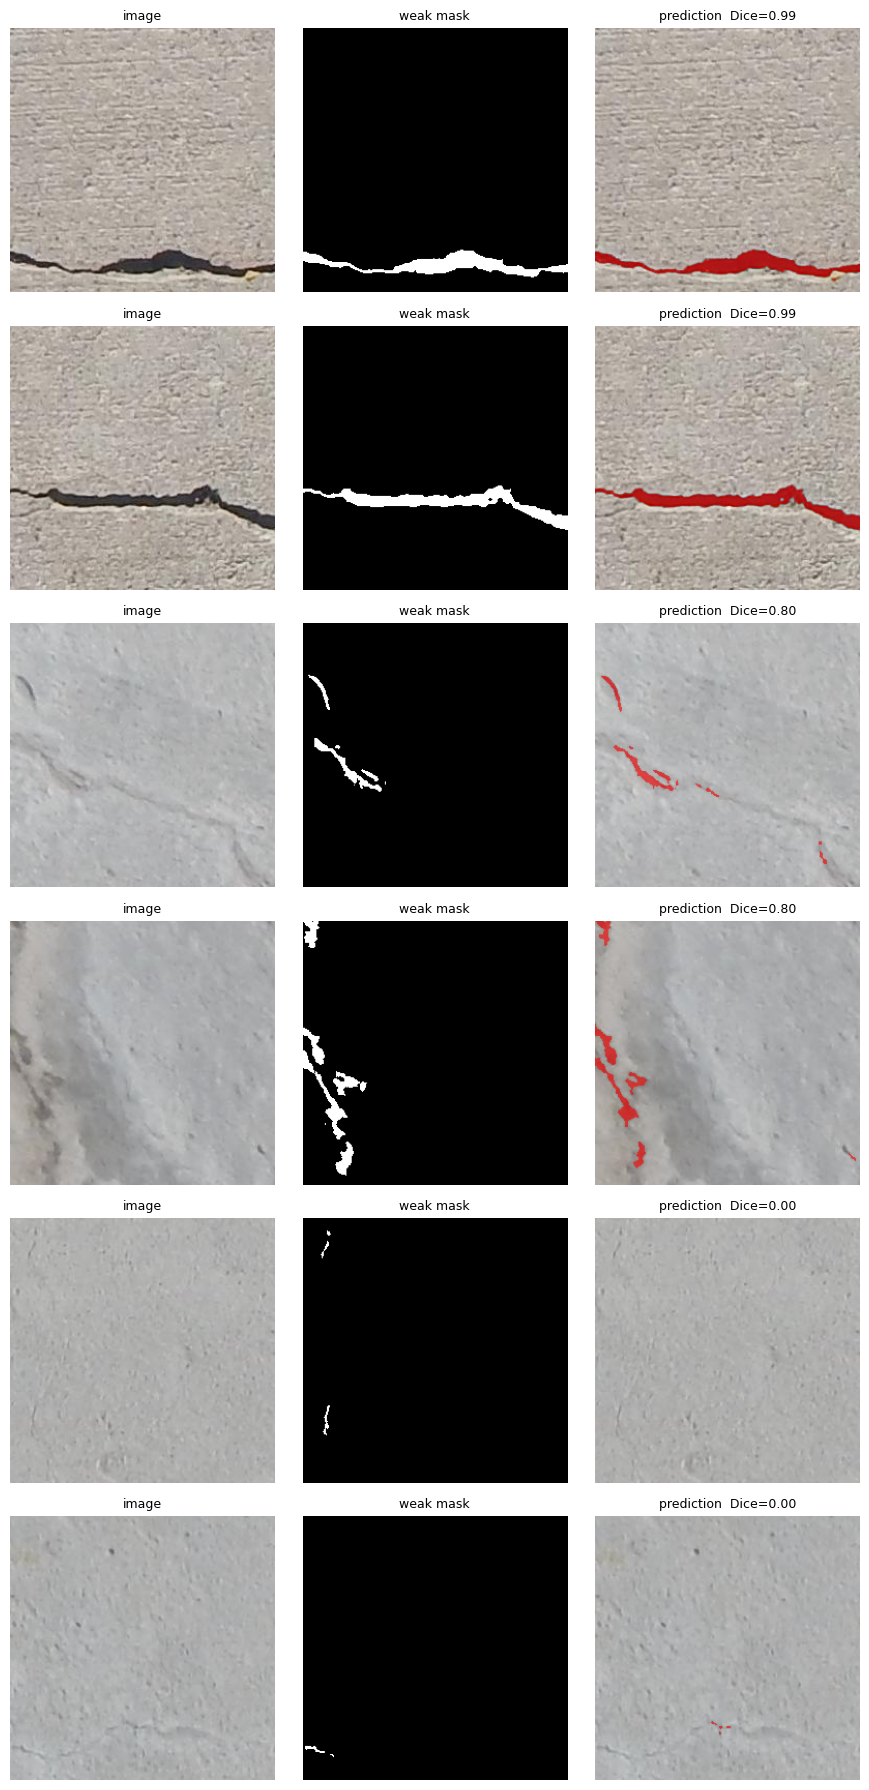

In [ ]:
# ===== Feature 3: choose threshold on VALIDATION, report on TEST, look at examples =====
thrs = [0.3, 0.4, 0.5, 0.6, 0.7]
cv_ = eval_counts(model, dl_va, thrs)
THR = max(thrs, key=lambda t: seg_metrics(cv_[t])["Dice"])
print("Threshold chosen on validation data:", THR)

tm = seg_metrics(eval_counts(model, dl_te, [THR])[THR])
print("\n=== TEST RESULTS (agreement with the WEAK masks) ===")
print({k: round(v, 4) for k, v in tm.items()})

# per-image analysis: best / typical / worst cases, and false alarms on uncracked images
@torch.no_grad()
def per_image(ds, thr):
    model.eval(); rows = []; k = 0
    for x, y in DataLoader(ds, batch_size=32, num_workers=2):
        pb = torch.sigmoid(model(x.to(dev)).float()) > thr; yb = y.to(dev) > 0.5
        inter = (pb & yb).flatten(1).sum(1).cpu().numpy(); ps = pb.flatten(1).sum(1).cpu().numpy(); ys = yb.flatten(1).sum(1).cpu().numpy()
        for j in range(len(x)):
            rows.append((ds.files[k], 2 * inter[j] / max(ps[j] + ys[j], 1), int(ps[j]), int(ys[j]))); k += 1
    return pd.DataFrame(rows, columns=["file", "dice", "pred_px", "gt_px"])

pi = per_image(dl_te.dataset, THR)
neg, posi = pi[pi.gt_px == 0], pi[pi.gt_px > 0].sort_values("dice", ascending=False).reset_index(drop=True)
print(f"Cracked test images: mean Dice {posi.dice.mean():.3f} | median {posi.dice.median():.3f}")
if len(neg):
    print(f"Uncracked test images with >50 predicted crack pixels (false alarms): {(neg.pred_px > 50).sum()} of {len(neg)}")

pick = list(posi.index[:2]) + list(posi.index[len(posi)//2 - 1: len(posi)//2 + 1]) + list(posi.index[-2:])
fig, axes = plt.subplots(len(pick), 3, figsize=(9, 3 * len(pick)))
for r_, i in enumerate(pick):
    f = posi.file[i]
    im = cv2.cvtColor(cv2.imread(f"{WEAK}/images/test/{f}"), cv2.COLOR_BGR2RGB)
    gm = cv2.imread(f"{WEAK}/masks/test/{os.path.splitext(f)[0]}.png", 0)
    x, _ = dl_te.dataset[dl_te.dataset.files.index(f)]
    with torch.no_grad():
        pm = (torch.sigmoid(model(x[None].to(dev)).float())[0, 0] > THR).cpu().numpy()
    pm = cv2.resize(pm.astype(np.uint8), (im.shape[1], im.shape[0]), interpolation=cv2.INTER_NEAREST)
    ov = im.copy(); ov[pm > 0] = (255, 0, 0)
    for c_, (a, t) in enumerate([(im, "image"), (gm, "weak mask"), (cv2.addWeighted(ov, 0.6, im, 0.4, 0), f"prediction  Dice={posi.dice[i]:.2f}")]):
        axes[r_, c_].imshow(a, cmap="gray" if a.ndim == 2 else None); axes[r_, c_].set_title(t, fontsize=9); axes[r_, c_].axis("off")
plt.tight_layout(); plt.show()

### 3D — save to Drive

In [ ]:
# ===== Feature 3: save model + settings to Google Drive =====
out = f"{BACKUP}/segmentation"
os.makedirs(out, exist_ok=True)
torch.save({"state_dict": model.state_dict(), "threshold": THR, "img_size": IMG, "base_channels": 32,
            "note": "trained on WEAK masks from classical measurement; not manual ground truth"}, f"{out}/unet_crack.pt")
json.dump({"threshold": THR, "test_metrics": tm}, open(f"{out}/segmentation_results.json", "w"), indent=2)
shutil.copy(f"{WEAK}/manifest.csv", out)
print("Saved to", out)

Saved to /content/drive/MyDrive/MINI_PROJECT/outputs/segmentation


## Checklist before you claim a feature is complete
- Dataset and label type match the task (proxy / weak labels - state this clearly).
- Train, validation and test sets are separate and documented (photo-aware split in Cell 0).
- Metrics come from the held-out test split; examples include failures, not only successes.
- Model weights, thresholds and settings are saved (Drive folder `MINI_PROJECT/outputs`).
- Limitations are written in the report: image-only assessment, weak/proxy labels, no physical-scale calibration.
- For a trustworthy Feature 2/3 evaluation, hand-annotate ~30-50 test images, replace the matching files in
  `/content/ext/weak/masks/test` and `/content/ext/weak/labels/test`, delete `*.cache` in `/content/ext/weak/labels`,
  and re-run the evaluation cells.

---
## If Colab disconnects midway
Colab wipes its disk when a session ends. Re-run Steps 1–5, then run the cell below to restore saved work
and skip the slow steps (continue from Step 9). To continue with the extensions, run **Cell 0 of Part 2** next
(the weak-label dataset is rebuilt by its own cell; Features 1A onward only need the restored features and labels).

In [ ]:
import shutil, os
for f in ["features_dinov2_vits14.npz", "crack_measurements.csv", "severity_labels.csv", "severity_cutoffs.json"]:
    shutil.copy(f"{BACKUP}/{f}", f"severity/{f}")
if os.path.exists(f"{BACKUP}/models"):
    shutil.copytree(f"{BACKUP}/models", "severity/models", dirs_exist_ok=True)
print("Restored. Continue from Step 9 (or Step 10 if models were restored).")

Restored. Continue from Step 9 (or Step 10 if models were restored).
